In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF
from functions import linear

In [2]:
#X,Y must be a box
Y=[(0,2*np.pi)]
n=3
A=np.zeros([6,3])
b=[1,1,100,1,1,0]
for i in range(n):
    A[i,i]=1
    A[n+1,i]=-1
X=[(linear,[A,b])]
norm=2
#DCP of f following cxvpy rules
def fcp(x):
    return -x[2]

def q1(x,z):
    return -z[1]

def q2(x,z):
    return z[0]+2*z[1]-2+x[1]
    
def q3(x,z):
    return -z[0]+2*z[1]-2
    #return -z[0]
#Curves
def p(y):
    return np.array([np.cos(y)[0],np.sin(y)[0]])
    
#DCP of g following cxvpy rules
def gcp(x,y):
    q=cp.hstack([q1(x[0:2],x[0:2]+x[2]*p(y)),q2(x[0:2],x[0:2]+x[2]*p(y)),q3(x[0:2],x[0:2]+x[2]*p(y))])
    return cp.max(q)
        
def g(x,y):
    return np.max([q1(x[0:2],x[0:2]+x[2]*p(y)),q2(x[0:2],x[0:2]+x[2]*p(y)),q3(x[0:2],x[0:2]+x[2]*p(y))])
    




def circle(c,r,N):
    x=np.ones(N)
    y=np.ones(N)
    t = np.linspace(0, 2*np.pi, N)
    for i in range(N):
        x[i]=c[0]+np.abs(r)*np.cos(t[i])
        y[i]=c[1]+np.abs(r)*np.sin(t[i])
    return x,y

def square(c,r,N):
    x=np.ones(N)
    y=np.ones(N)
    t = np.linspace(0, 2*np.pi, N)
    for i in range(N):
        x[i]=c[0]+r*np.cos(t[i])
        y[i]=c[0]+r*np.sin(t[i])
    return x,y


def line(x,coeff):
    a1=coeff[0]
    a2=coeff[1]
    b=coeff[2]
    if a2!=0:
        return x,[(-a1*x[0]-b)/a2,(-a1*x[1]-b)/a2]
    else:
        print("retta verticale")
        return [-b/a1,-b/a1],x

In [3]:
x0=np.array([0,0,0])
y0=np.array([[1]])

In [5]:
res=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y)
print(res[0])

Time 0.14840126037597656
Time upper problem 0.0871427059173584
Time lower problem 0.061258554458618164
Feasibility 1.492257983848333e-10
Final rho 1
Rho increases 0
Optimal value -0.4222912360834419
Value function call 4
[-0.21114562  0.42229124  0.42229124]


In [6]:
res=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

Time 2.1666669845581055
Time upper problem 1.9214904308319092
Time lower problem 0.2441411018371582
Feasibility 4.072679498645648e-06
Optimal value -0.4222926639680039
Value function call 20


In [7]:
res=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1000)

Time 0.18476223945617676
Time upper problem 0.11564135551452637
Time lower problem 0.06912088394165039
Feasibility -0.0004219792408890477
Optimal value -0.42229100579581236
Optimality cuts 2
Feasibility cuts 3
Value function calls 5


In [8]:
res=AlgBF(x0,y0,fcp,gcp,g,X,Y)

Time 0.13507556915283203
Time upper problem 0.07027149200439453
Time lower problem 0.0648040771484375
Feasibility 1.4972134643187474e-10
Optimal value -0.42229123608360114
Value function call 3


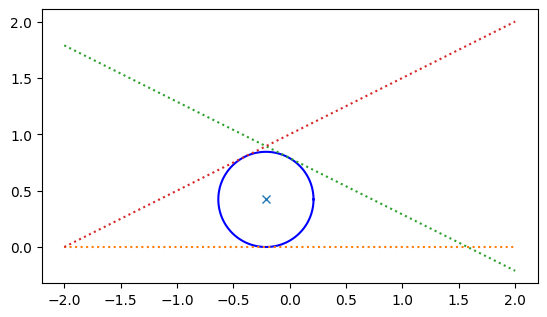

In [8]:
N = 400
t = np.linspace(Y[0][0], Y[0][1], N)
x=np.ones(N)
y=np.ones(N)
for i in range(N):
    x[i], y[i]= p(np.array([t[i]]))

fig, ax = plt.subplots()
#ax.plot(x, y, "k")
ax.set(aspect=1)

center=res[0][0:2]
radius=res[0][2]


coeff1=[q1(center,np.array([1,0]))-q1(center,np.array([0,0])),q1(center,np.array([0,1]))-q1(center,np.array([0,0])),q1(center,np.array([0,0]))]
coeff2=[q2(center,np.array([1,0]))-q2(center,np.array([0,0])),q2(center,np.array([0,1]))-q2(center,np.array([0,0])),q2(center,np.array([0,0]))]
coeff3=[q3(center,np.array([1,0]))-q3(center,np.array([0,0])),q3(center,np.array([0,1]))-q3(center,np.array([0,0])),q3(center,np.array([0,0]))]


x1,y1=circle(center,radius,N)
ax.plot(x1, y1, "b")
ax.plot(center[0],center[1],"x")
ax.plot(line([-2,2],coeff1)[0],line([-2,2],coeff1)[1], linestyle = 'dotted')
ax.plot(line([-2,2],coeff2)[0],line([-2,2],coeff2)[1], linestyle = 'dotted')
ax.plot(line([-2,2],coeff3)[0],line([-2,2],coeff3)[1], linestyle = 'dotted')

In [9]:

print(q2(center,np.array([1,0]))-q2(center,np.array([0,0])))
print(q2(center,np.array([0,1]))-q2(center,np.array([0,0])))
print(q2(center,np.array([0,0])))
coeff2=[q2(center,np.array([1,0]))-q2(center,np.array([0,0])),q2(center,np.array([0,1]))-q2(center,np.array([0,0])),q2(center,np.array([0,0]))]

1.0
2.0
-1.5777087640663252


In [10]:
print(line([-1,1],coeff2))

([-1, 1], [np.float64(1.2888543820331626), np.float64(0.2888543820331626)])
